# Smart Waste Classification Using Convolutional Neural Networks
**AI303 | Fall 2026–2027 | Google Colab-ready**

**Research paper:** Islam et al. (2025), *Towards sustainable solutions: Effective waste classification framework via enhanced deep convolutional neural networks*, PLOS ONE.  
Paper: https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0324294  
**Paper-linked dataset:** https://www.kaggle.com/datasets/mostafaabla/garbage-classification

**What this notebook does:** downloads the Kaggle dataset **directly in Colab (no manual ZIP upload)**, detects image categories, performs EDA and stratified train/validation/test splitting, trains a custom CNN and a DenseNet201 baseline, reports **8 metrics**, and generates graphs and prediction examples.

**Research integrity:** The paper uses a more elaborate DenseNet201 + squeeze-and-excitation/parallel CNN approach. Standard DenseNet201 here is a **comparison baseline, not an exact reproduction**. Your 70/15/15 split is your own protocol; do not compare numbers as if identical experiments. Run the notebook before claiming results.


## 1 — Setup
In Google Colab, choose **Runtime → Change runtime type → T4 GPU**, if available. Then run cells **in order**. You do **not** need to mount Google Drive or upload the dataset ZIP.

In [ ]:
%pip -q install kagglehub scikit-learn pandas matplotlib seaborn pillow

In [ ]:
import os, random, hashlib, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef, confusion_matrix,
    classification_report, log_loss)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2 — Download the exact paper-linked dataset
The download runs on Colab's machine, avoiding browser uploads that stop halfway. If Kaggle requires authentication, follow the error's instructions and authenticate to Kaggle, then rerun.

In [ ]:
DATASET_HANDLE = 'mostafaabla/garbage-classification'
dataset_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
print('Dataset downloaded to:', dataset_root)
print('Exists:', dataset_root.exists())


Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset downloaded to: /kaggle/input/garbage-classification
Exists: True


## 3 — Detect images and classes
This scans folders recursively and uses the **nearest non-generic parent directory** as the category. Inspect the printed categories before training. If the downloaded dataset layout differs, adjust `GENERIC_DIRS` and rerun.

In [ ]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
GENERIC_DIRS = {'train', 'training', 'test', 'testing', 'valid', 'validation',
                'images', 'image', 'data', 'dataset', 'garbage_classification',
                'garbage classification', 'garbage-classification', 'trash'}
paths = [p for p in dataset_root.rglob('*')
         if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
print('Images found:', len(paths))
if not paths:
    raise RuntimeError('No image files found. Check dataset download and its folder structure.')

def category_for(p):
    for parent in p.parents:
        if parent == dataset_root:
            break
        if parent.name.lower() not in GENERIC_DIRS:
            return parent.name
    return p.parent.name

records = pd.DataFrame({'path': [str(p) for p in paths],
                        'class_name': [category_for(p) for p in paths]})
print('\nDetected class counts:')
print(records.class_name.value_counts().sort_index().to_string())
print('\nExample image paths:')
for p in records.path.head(5): print(p)
if records.class_name.nunique() < 2:
    raise RuntimeError('Only one class detected. Inspect folder structure and fix category_for().')

if len(records) < 1000 or not (5 <= records.class_name.nunique() <= 20):
    print('WARNING: Unexpected dataset count or classes. Review paths before training.')
print('Expected paper reference: 15,515 images / 12 classes (downloaded version may differ).')


Images found: 15515

Detected class counts:
class_name
battery         945
biological      985
brown-glass     607
cardboard       891
clothes        5325
green-glass     629
metal           769
paper          1050
plastic         865
shoes          1977
trash           697
white-glass     775

Example image paths:
/kaggle/input/garbage-classification/garbage_classification/metal/metal375.jpg
/kaggle/input/garbage-classification/garbage_classification/metal/metal561.jpg
/kaggle/input/garbage-classification/garbage_classification/metal/metal341.jpg
/kaggle/input/garbage-classification/garbage_classification/metal/metal688.jpg
/kaggle/input/garbage-classification/garbage_classification/metal/metal374.jpg
Expected paper reference: 15,515 images / 12 classes (downloaded version may differ).


## 4 — Data quality, EDA, and split
Exact duplicate files are removed using SHA-256 before splitting, to reduce data leakage. The split is **70% train, 15% validation, 15% test**, stratified by class. Near-duplicates or related scenes can still cause leakage; document this limitation.

Checking exact duplicate image files...
Removed exact duplicates: 19
Unique images: 15496
Train: 10847 | Validation: 2324 | Test: 2325
              All  Train  Validation  Test
class_name                                
battery       945    661         142   142
biological    985    689         148   148
brown-glass   607    425          91    91
cardboard     891    624         133   134
clothes      5324   3727         798   799
green-glass   614    430          92    92
metal         769    538         116   115
paper        1050    735         157   158
plastic       863    604         130   129
shoes        1977   1384         296   297
trash         697    488         105   104
white-glass   774    542         116   116


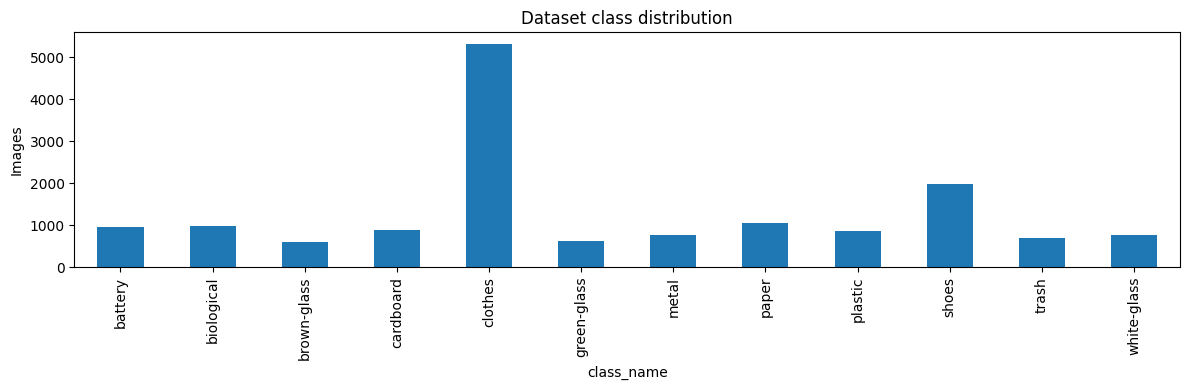

In [ ]:
print('Checking exact duplicate image files...')
records['sha256'] = records.path.map(lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest())
duplicates = int(records.duplicated('sha256').sum())
records = records.drop_duplicates('sha256').reset_index(drop=True)
print('Removed exact duplicates:', duplicates)
print('Unique images:', len(records))

classes = sorted(records.class_name.unique())
class_to_id = {name: i for i, name in enumerate(classes)}
records['label'] = records.class_name.map(class_to_id)
assert records.class_name.value_counts().min() >= 7, 'A class has too few images for a stratified 70/15/15 split.'

train_df, rest_df = train_test_split(records, test_size=0.30, stratify=records.label, random_state=SEED)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df.label, random_state=SEED)
print('Train:', len(train_df), '| Validation:', len(val_df), '| Test:', len(test_df))
print(pd.DataFrame({
    'All': records.class_name.value_counts(),
    'Train': train_df.class_name.value_counts(),
    'Validation': val_df.class_name.value_counts(),
    'Test': test_df.class_name.value_counts()
}).fillna(0).astype(int).sort_index())

plt.figure(figsize=(12, 4))
records.class_name.value_counts().sort_index().plot(kind='bar')
plt.title('Dataset class distribution'); plt.ylabel('Images'); plt.tight_layout(); plt.show()


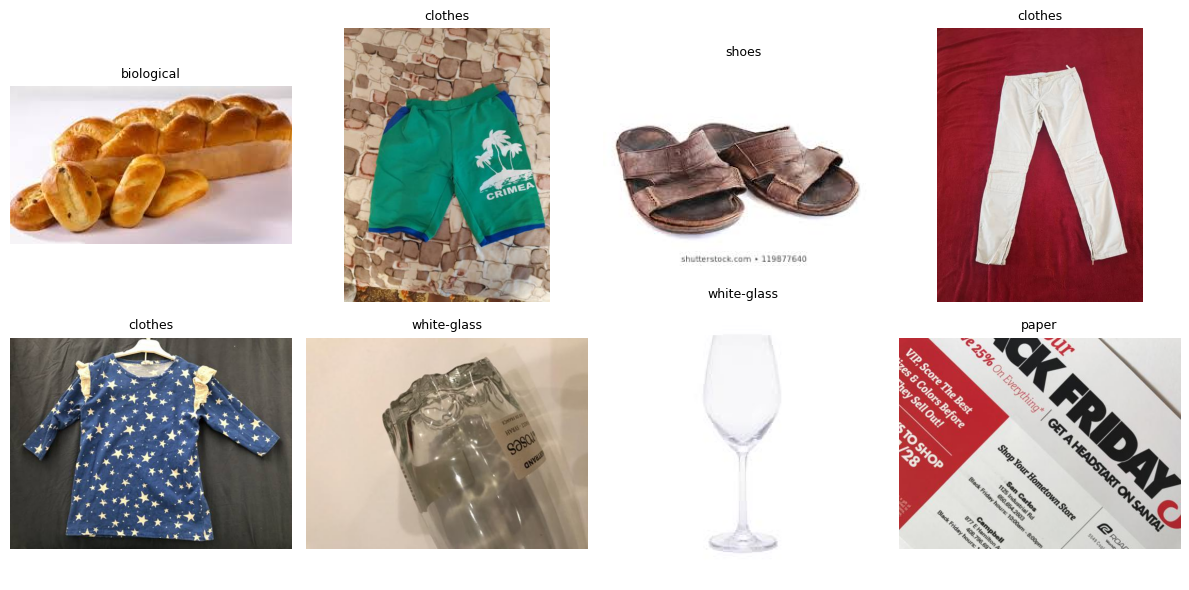

In [ ]:
sample = records.sample(min(8, len(records)), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat: ax.axis('off')
for ax, (_, item) in zip(axes.flat, sample.iterrows()):
    try:
        with Image.open(item.path) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(item.class_name, fontsize=9)
        ax.axis('off')
    except Exception as e:
        print('Could not display:', item.path, e)
plt.tight_layout(); plt.show()


## 5 — Image pipeline
Both models receive the **same train/validation/test data**. The augmentation is applied **only during training**. TensorFlow streams images from disk instead of loading the entire dataset into RAM.

In [ ]:
SIZE = (170, 170)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(classes)

def decode_image(path, label):
    data = tf.io.read_file(path)
    img = tf.io.decode_image(data, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, SIZE)
    return tf.cast(img, tf.float32), label

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df.path.astype(str).to_numpy(),
        df.label.astype('int32').to_numpy()))
    if training:
        ds = ds.shuffle(min(len(df), 5000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.07),
    tf.keras.layers.RandomZoom(0.10),
], name='training_augmentation')
print('Classes:', classes)


Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


## 6A — Model 0: Multilayer Perceptron (MLP) baseline
This baseline directly connects to AI303 Lab 4. Images are downsampled to 48×48 and flattened to avoid an enormous fully connected network. Unlike CNN, the MLP does not explicitly exploit local spatial patterns. **This model is not from the paper.**

In [ ]:
def callbacks(prefix):
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5),
        tf.keras.callbacks.ModelCheckpoint(f'/content/{prefix}.keras',
                                           monitor='val_loss', save_best_only=True)
    ]

def make_mlp_dataset(ds):
    return ds.map(
        lambda x,y: (tf.image.resize(x, (48,48)), y),
        num_parallel_calls=AUTOTUNE
    ).prefetch(AUTOTUNE)

mlp_train_ds = make_mlp_dataset(train_ds)
mlp_val_ds = make_mlp_dataset(val_ds)
mlp_test_ds = make_mlp_dataset(test_ds)

mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(48,48,3)),
    tf.keras.layers.Rescaling(1/255.0),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
], name='MLP_baseline')
mlp.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])
mlp.summary()
t0=time.time()
history_mlp = mlp.fit(mlp_train_ds, validation_data=mlp_val_ds, epochs=8,
                      callbacks=callbacks('smart_waste_mlp'))
mlp_seconds=time.time()-t0

Model: "MLP_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6912)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     1,769,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,804,172 (6.88 MB)

 Trainable params: 1,804,172 (6.88 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 27s 64ms/step - accuracy: 0.3248 - loss: 2.1651 - val_accuracy: 0.3498 - val_loss: 1.8019 - learning_rate: 0.0010
Epoch 2/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.3449 - loss: 1.9566 - val_accuracy: 0.3412 - val_loss: 1.8483 - learning_rate: 0.0010
Epoch 3/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 48ms/step - accuracy: 0.3443 - loss: 1.9468 - val_accuracy: 0.3589 - val_loss: 1.7327 - learning_rate: 0.0010
Epoch 4/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 48ms/step - accuracy: 0.3442 - loss: 1.9312 - val_accuracy: 0.3606 - val_loss: 1.7860 - learning_rate: 0.0010
Epoch 5/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - accuracy: 0.3595 - loss: 1.8517 - val_accuracy: 0.3799 - val_loss: 1.7025 - learning_rate: 0.0010
Epoch 6/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - accuracy: 0.3654 - loss: 1.8124 - val_accuracy: 0.3898 - val_loss: 1.6907 - learning_rate: 0.0010
Epoch 7/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.3729 - loss: 1.

## 6 — Model A: Custom CNN
A small architecture appropriate for AI303: convolution, max-pooling, dropout, dense classification. The output has one softmax neuron per waste category.

In [ ]:
def build_custom_cnn():
    inputs = tf.keras.Input(shape=(*SIZE, 3))
    x = tf.keras.layers.Rescaling(1/255.0)(inputs)
    x = tf.keras.models.clone_model(augmentation)(x)
    for filters in (32, 64, 128):
        x = tf.keras.layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs, name='Custom_CNN')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def callbacks(prefix):
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5),
        tf.keras.callbacks.ModelCheckpoint(f'/content/{prefix}.keras',
                                           monitor='val_loss', save_best_only=True)
    ]

EPOCHS_CNN = 12
cnn = build_custom_cnn()
cnn.summary()
t0 = time.time()
history_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN,
                      callbacks=callbacks('smart_waste_custom_cnn'))
cnn_seconds = time.time() - t0


Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 170, 170, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 170, 170, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 170, 170, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 170, 170, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 85, 85, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 85, 85, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 42, 42, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 42, 42, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 21, 21, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,308 (434.80 KB)

 Trainable params: 111,308 (434.80 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
339/339 ━━━━━━━━━━━━━━━━━━━━ 36s 89ms/step - accuracy: 0.4231 - loss: 1.8059 - val_accuracy: 0.5090 - val_loss: 1.5143 - learning_rate: 0.0010
Epoch 2/12
339/339 ━━━━━━━━━━━━━━━━━━━━ 18s 52ms/step - accuracy: 0.5183 - loss: 1.4868 - val_accuracy: 0.5189 - val_loss: 1.4063 - learning_rate: 0.0010
Epoch 3/12
339/339 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.5436 - loss: 1.3821 - val_accuracy: 0.5972 - val_loss: 1.2074 - learning_rate: 0.0010
Epoch 4/12
339/339 ━━━━━━━━━━━━━━━━━━━━ 18s 54ms/step - accuracy: 0.5563 - loss: 1.3200 - val_accuracy: 0.5865 - val_loss: 1.2002 - learning_rate: 0.0010
Epoch 5/12
339/339 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - accuracy: 0.5756 - loss: 1.2654 - val_accuracy: 0.6231 - val_loss: 1.1384 - learning_rate: 0.0010
Epoch 6/12
339/339 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.5916 - loss: 1.2318 - val_accuracy: 0.6317 - val_loss: 1.0935 - learning_rate: 0.0010
Epoch 7/12
339/339 ━━━━━━━━━━━━━━━━━━━━ 17s 51ms/step - accuracy: 0.5984 - l

## 7 — Model B: DenseNet201 transfer learning
Pretrained ImageNet DenseNet201 is used as a **baseline**. DenseNet201's preprocessing is included and pretrained convolution layers are frozen to keep Colab training practical. **It is not the paper's full proposed model.**

In [ ]:
def build_densenet201():
    backbone = tf.keras.applications.DenseNet201(
        include_top=False, weights='imagenet', input_shape=(*SIZE, 3))
    backbone.trainable = False
    inputs = tf.keras.Input(shape=(*SIZE, 3))
    x = tf.keras.models.clone_model(augmentation)(inputs)
    x = tf.keras.applications.densenet.preprocess_input(x)
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs, name='DenseNet201_Baseline')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

EPOCHS_DENSE = 8
dense = build_densenet201()
dense.summary()
t0 = time.time()
history_dense = dense.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_DENSE,
                          callbacks=callbacks('smart_waste_densenet201'))
dense_seconds = time.time() - t0


74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet201_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 170, 170, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 170, 170, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 170, 170, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 170, 170, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 170, 170, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 5, 5, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 12)             │        23,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,345,036 (69.98 MB)

 Trainable params: 23,052 (90.05 KB)

 Non-trainable params: 18,321,984 (69.89 MB)

Epoch 1/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 110s 246ms/step - accuracy: 0.7940 - loss: 0.6924 - val_accuracy: 0.9243 - val_loss: 0.2431 - learning_rate: 0.0010
Epoch 2/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 64s 190ms/step - accuracy: 0.9049 - loss: 0.3051 - val_accuracy: 0.9359 - val_loss: 0.2259 - learning_rate: 0.0010
Epoch 3/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 65s 191ms/step - accuracy: 0.9152 - loss: 0.2678 - val_accuracy: 0.9423 - val_loss: 0.1935 - learning_rate: 0.0010
Epoch 4/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 64s 189ms/step - accuracy: 0.9273 - loss: 0.2194 - val_accuracy: 0.9497 - val_loss: 0.1832 - learning_rate: 0.0010
Epoch 5/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 65s 190ms/step - accuracy: 0.9245 - loss: 0.2278 - val_accuracy: 0.9462 - val_loss: 0.1749 - learning_rate: 0.0010
Epoch 6/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 61s 181ms/step - accuracy: 0.9324 - loss: 0.2085 - val_accuracy: 0.9458 - val_loss: 0.1812 - learning_rate: 0.0010
Epoch 7/8
339/339 ━━━━━━━━━━━━━━━━━━━━ 64s 189ms/step - accuracy: 0.9382 - 

## 8 — Evaluation: more than four metrics
Compute **accuracy, macro precision, macro recall, macro F1, weighted F1, balanced accuracy, Cohen's kappa, and Matthews correlation coefficient**. Use the untouched test set only for final evaluation.

73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step

 MLP baseline
              precision    recall  f1-score   support

     battery       0.00      0.00      0.00       142
  biological       0.59      0.20      0.30       148
 brown-glass       0.00      0.00      0.00        91
   cardboard       0.26      0.20      0.23       134
     clothes       0.59      0.93      0.72       799
 green-glass       0.00      0.00      0.00        92
       metal       0.00      0.00      0.00       115
       paper       0.18      0.27      0.21       158
     plastic       0.00      0.00      0.00       129
       shoes       0.22      0.42      0.29       297
       trash       0.00      0.00      0.00       104
 white-glass       0.32      0.29      0.31       116

    accuracy                           0.43      2325
   macro avg       0.18      0.19      0.17      2325
weighted avg       0.31      0.43      0.35      2325



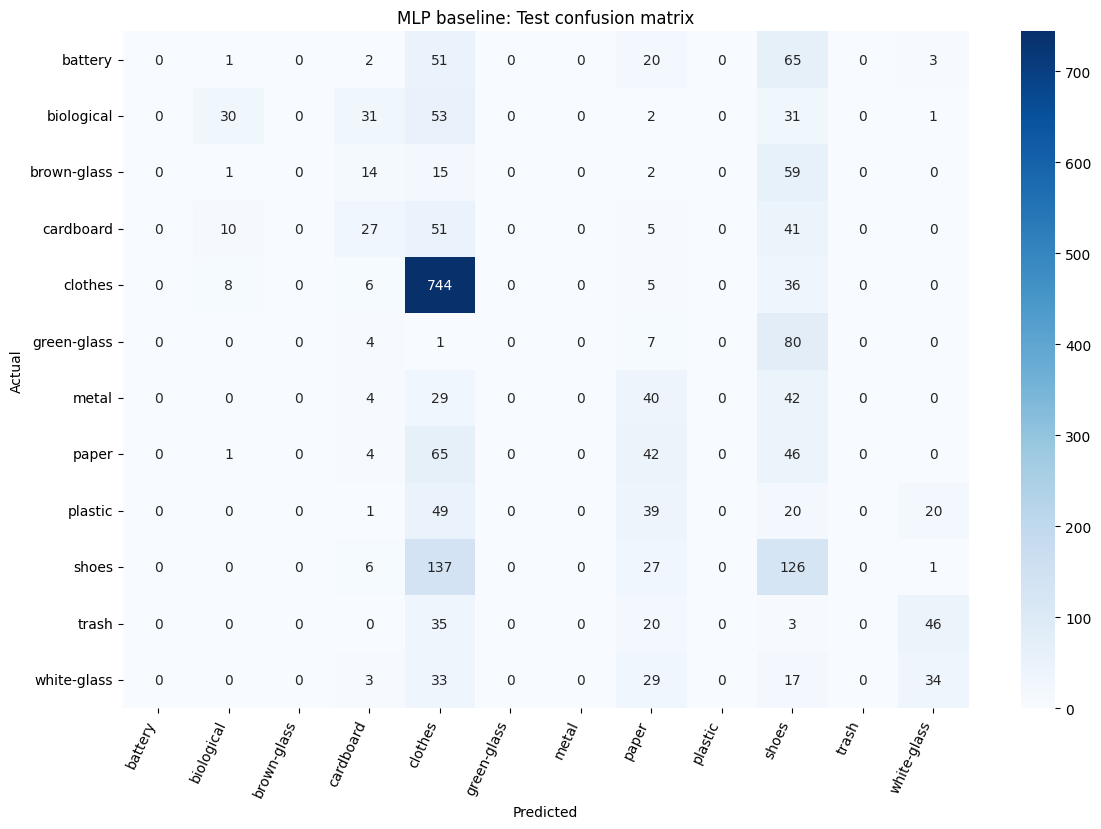

73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step

 Custom CNN
              precision    recall  f1-score   support

     battery       0.52      0.60      0.55       142
  biological       0.72      0.48      0.57       148
 brown-glass       0.71      0.59      0.65        91
   cardboard       0.62      0.79      0.70       134
     clothes       0.74      0.93      0.83       799
 green-glass       0.79      0.93      0.86        92
       metal       0.36      0.08      0.13       115
       paper       0.54      0.71      0.61       158
     plastic       0.64      0.33      0.43       129
       shoes       0.53      0.35      0.42       297
       trash       0.58      0.71      0.64       104
 white-glass       0.49      0.31      0.38       116

    accuracy                           0.66      2325
   macro avg       0.60      0.57      0.56      2325
weighted avg       0.63      0.66      0.63      2325



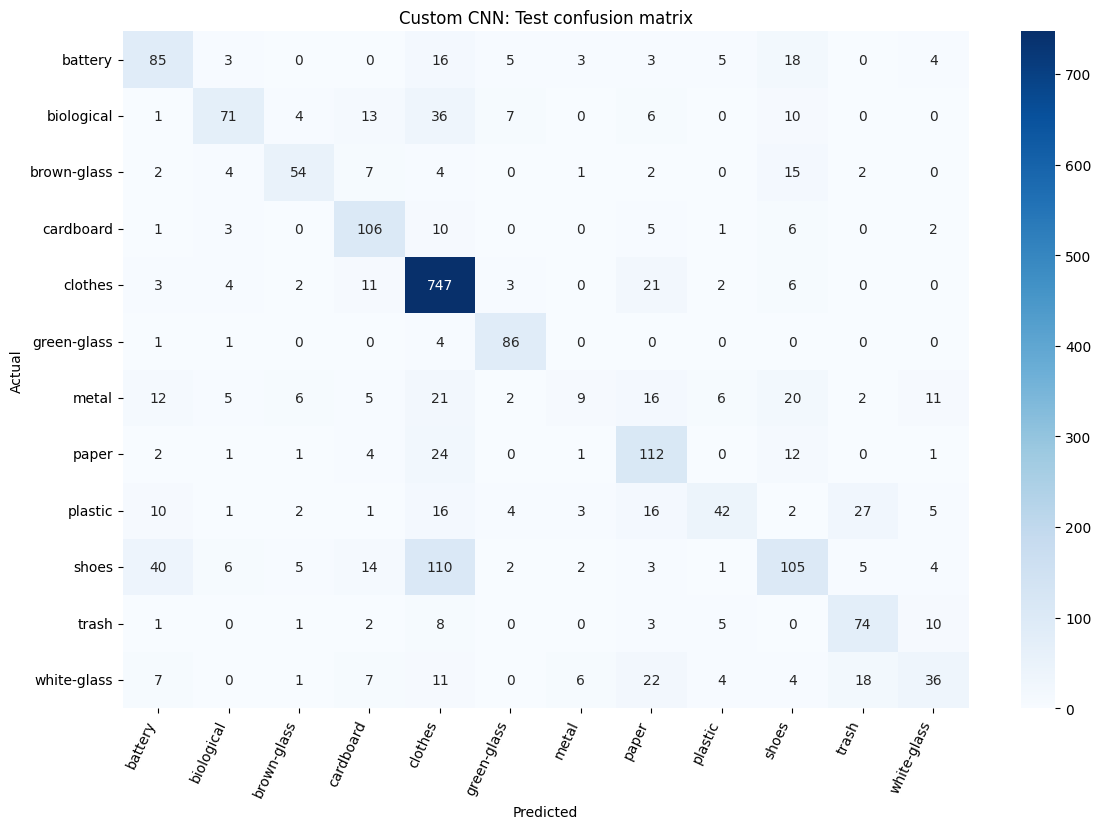

73/73 ━━━━━━━━━━━━━━━━━━━━ 28s 311ms/step

 DenseNet201 baseline
              precision    recall  f1-score   support

     battery       0.96      0.96      0.96       142
  biological       0.97      0.97      0.97       148
 brown-glass       0.95      0.89      0.92        91
   cardboard       0.95      0.92      0.93       134
     clothes       0.98      0.99      0.99       799
 green-glass       0.94      0.97      0.95        92
       metal       0.84      0.90      0.87       115
       paper       0.93      0.89      0.91       158
     plastic       0.91      0.81      0.86       129
       shoes       0.96      0.98      0.97       297
       trash       0.98      0.93      0.96       104
 white-glass       0.83      0.90      0.86       116

    accuracy                           0.95      2325
   macro avg       0.93      0.93      0.93      2325
weighted avg       0.95      0.95      0.95      2325



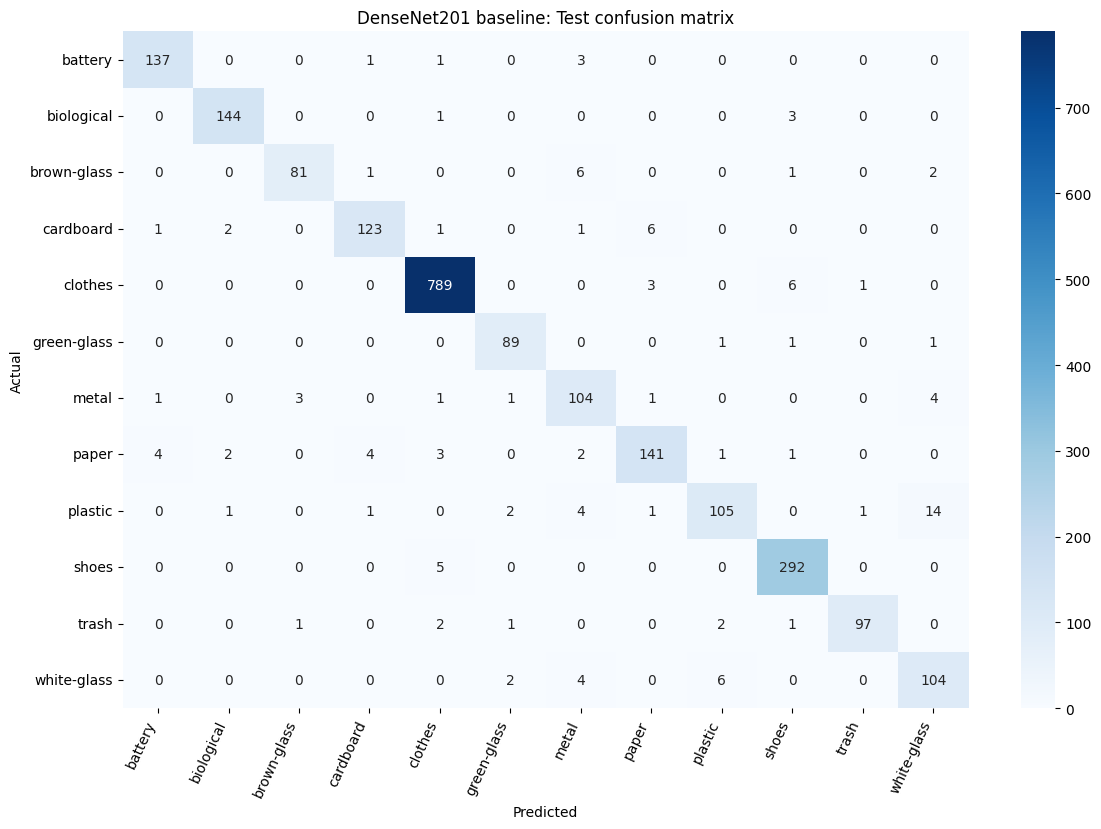

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Balanced accuracy,Macro specificity,Cohen kappa,MCC,Training seconds,Parameters
0,MLP baseline,0.431398,0.180409,0.193211,0.171981,0.347440,0.193211,0.939706,0.260677,0.275970,146.7,1804172
1,Custom CNN,0.656774,0.602584,0.568383,0.564042,0.627541,0.568383,0.965075,0.578160,0.583530,243.8,111308
2,DenseNet201 baseline,0.948817,0.932629,0.926981,0.929144,0.948698,0.926981,0.995218,0.938779,0.938838,556.1,18345036


Saved: /content/smart_waste_model_comparison.csv


In [ ]:
y_true = test_df.label.to_numpy()
def evaluate(model, name, seconds, dataset=None):
    probabilities = model.predict(dataset if dataset is not None else test_ds, verbose=1)
    predicted = probabilities.argmax(axis=1)
    cm = confusion_matrix(y_true, predicted, labels=list(range(NUM_CLASSES)))

    specificities = []
    for i in range(NUM_CLASSES):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        tn = cm.sum() - tp - fp - fn
        specificities.append(tn / (tn + fp) if (tn + fp) else 0.0)
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_true, predicted),
        'Macro precision': precision_score(y_true, predicted, average='macro', zero_division=0),
        'Macro recall': recall_score(y_true, predicted, average='macro', zero_division=0),
        'Macro F1': f1_score(y_true, predicted, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_true, predicted, average='weighted', zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y_true, predicted),
        'Macro specificity': float(np.mean(specificities)),
        'Cohen kappa': cohen_kappa_score(y_true, predicted),
        'MCC': matthews_corrcoef(y_true, predicted),
        'Training seconds': round(seconds, 1),
        'Parameters': model.count_params()
    }
    print('\n', name)
    print(classification_report(y_true, predicted, target_names=classes, zero_division=0))
    plt.figure(figsize=(max(9, NUM_CLASSES), max(7, NUM_CLASSES * 0.7)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title(f'{name}: Test confusion matrix')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.xticks(rotation=65, ha='right'); plt.tight_layout(); plt.show()
    return metrics

results = pd.DataFrame([
    evaluate(mlp, 'MLP baseline', mlp_seconds, mlp_test_ds),
    evaluate(cnn, 'Custom CNN', cnn_seconds),
    evaluate(dense, 'DenseNet201 baseline', dense_seconds)
])
display(results)
results.to_csv('/content/smart_waste_model_comparison.csv', index=False)
print('Saved: /content/smart_waste_model_comparison.csv')


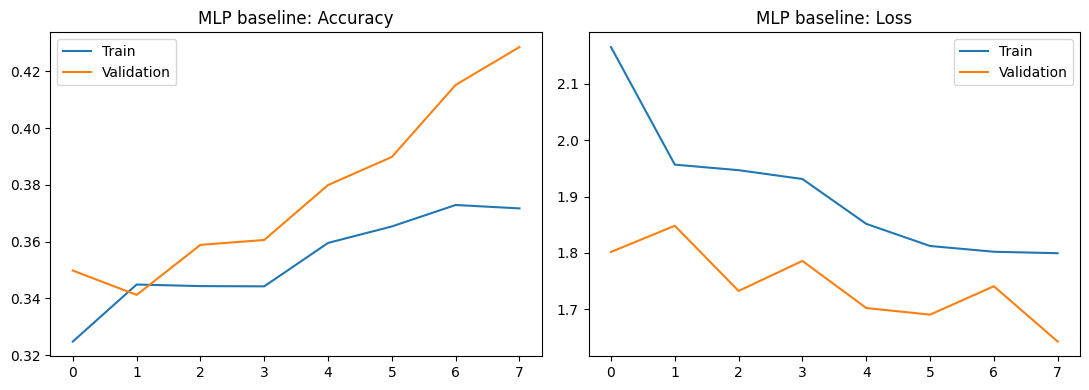

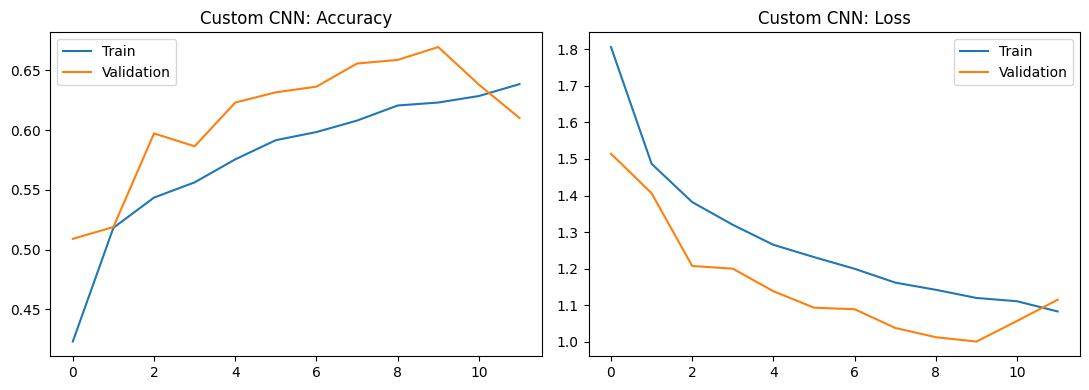

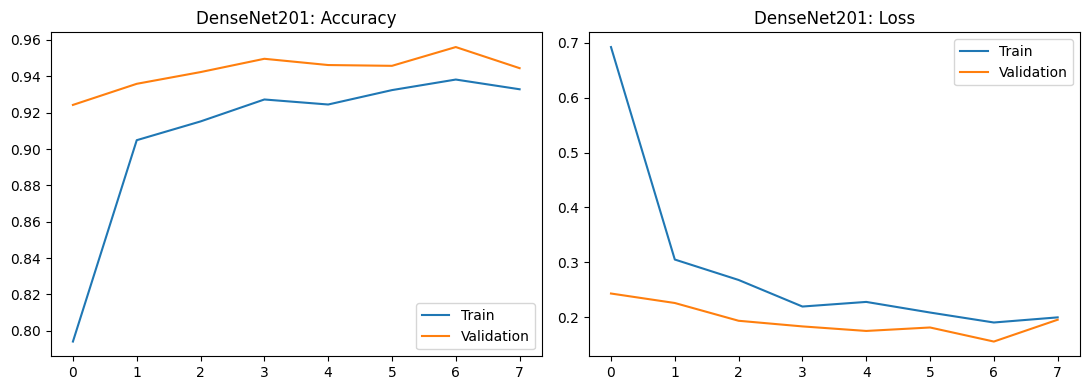

In [ ]:
for name, history in [('MLP baseline', history_mlp), ('Custom CNN', history_cnn), ('DenseNet201', history_dense)]:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history.history['accuracy'], label='Train')
    ax[0].plot(history.history['val_accuracy'], label='Validation')
    ax[0].set_title(f'{name}: Accuracy'); ax[0].legend()
    ax[1].plot(history.history['loss'], label='Train')
    ax[1].plot(history.history['val_loss'], label='Validation')
    ax[1].set_title(f'{name}: Loss'); ax[1].legend()
    plt.tight_layout(); plt.show()


## 9 — Paper comparison (fill in from the paper)
**Paper:** https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0324294

The paper uses a more advanced architecture incorporating DenseNet201 and squeeze-and-excitation / parallel CNN components. The two models above are **Custom CNN** and **standard DenseNet201 transfer learning**; do not describe the latter as an exact reproduction.

To make a defensible numerical comparison, record the paper's **specific dataset, metric definition, train/test split, and reported result** from its results table, then explain differences in model design, preprocessing, data splitting, and compute. **Do not invent paper scores.**

| Architecture | Test accuracy | Macro F1 | Notes |
|---|---|---|---|
| Custom CNN (this notebook) | See evaluation output | See evaluation output | Your model |
| DenseNet201 baseline (this notebook) | See evaluation output | See evaluation output | Standard pretrained backbone |
| Paper's proposed enhanced CNN | Enter verified paper value | Enter if reported | Not directly reproduced; protocol may differ |

**Theory:** Custom CNN has fewer parameters and trains from scratch, whereas pretrained DenseNet201 transfers visual features and may generalize better but is heavier. The paper's enhanced architecture adds additional feature/attention components.

**Future work:** (1) Reproduce the exact paper architecture and split; (2) test additional datasets; (3) evaluate robustness to low lighting and clutter; (4) optimize for mobile deployment; (5) use class-aware augmentation for imbalanced categories.


## 10 — Predict one uploaded image (optional)
Run after training. Colab will ask you to upload a JPG/PNG; this is **one test photo**, not the dataset.

In [ ]:
 #Optional: uncomment these lines to classify a new photo.
 from google.colab import files
 uploaded = files.upload()
 filename = next(iter(uploaded))
 image = tf.keras.utils.load_img(filename, target_size=SIZE)
 x = np.expand_dims(tf.keras.utils.img_to_array(image), axis=0)
 probs = dense.predict(x, verbose=0)[0]
 print('Prediction:', classes[int(np.argmax(probs))], '| Confidence:', round(float(probs.max()), 3))


Saving images (1).jpg to images (1).jpg
Prediction: plastic | Confidence: 0.845


## AI303 submission checklist
- [ ] Team of **6–8**, with names, IDs, roles and TA approval.
- [ ] Paper title, authors, publication year (2025), DOI/link.
- [ ] Dataset source, exact local image count, category distribution, and 70/15/15 split.
- [ ] Explain duplicates, class imbalance, resizing, normalization, augmentation.
- [ ] Include model summaries, input/output shapes, parameters, hyperparameters.
- [ ] Report **more than four metrics** with real Colab outputs.
- [ ] Compare models experimentally and theoretically.
- [ ] Verify and cite the paper's **actual** reported result for the **same dataset**.
- [ ] Propose **at least two** future improvements.


## 11 — Published paper benchmark versus our test results

The paper's **Table 11** reports **96.65% accuracy** on the 12-class **Waste Classification** dataset for its proposed DenseNet201 + parallel SE-CNN architecture. This is a published reference, **not a result obtained by this notebook**.

**Important:** Different data splits, duplicate handling, model architectures, training budgets, and preprocessing can make the numbers not directly comparable. Use the table to discuss these differences rather than claiming to reproduce the paper.

Source: https://doi.org/10.1371/journal.pone.0324294.t011


In [ ]:
paper_accuracy = 0.9665
comparison = results[['Model','Accuracy','Macro F1','Macro specificity','Parameters','Training seconds']].copy()
comparison['Accuracy (%)'] = comparison['Accuracy'] * 100
comparison['Gap to paper (percentage points)'] = comparison['Accuracy (%)'] - paper_accuracy * 100
display(comparison[['Model','Accuracy (%)','Macro F1','Macro specificity',
                    'Parameters','Training seconds','Gap to paper (percentage points)']])
print('Paper (2025) proposed DenseNet201 + Parallel SE-CNN: 96.65% accuracy on 12-class Waste Classification dataset.')
print('This comparison is descriptive only; experimental protocols may differ.')
comparison.to_csv('/content/smart_waste_paper_comparison.csv', index=False)


,Model,Accuracy (%),Macro F1,Macro specificity,Parameters,Training seconds,Gap to paper (percentage points)
0,MLP baseline,43.139785,0.171981,0.939706,1804172,146.7,-53.510215
1,Custom CNN,65.677419,0.564042,0.965075,111308,243.8,-30.972581
2,DenseNet201 baseline,94.881720,0.929144,0.995218,18345036,556.1,-1.768280


Paper (2025) proposed DenseNet201 + Parallel SE-CNN: 96.65% accuracy on 12-class Waste Classification dataset.
This comparison is descriptive only; experimental protocols may differ.


## 12 — Optional Gradio image upload demo
Upload a photo and get the predicted waste class. The app does **not** determine local recycling rules, and model predictions may be wrong. Use only after training.

In [ ]:
%pip -q install gradio
import gradio as gr

def classify_waste(image):
    if image is None:
        return {}
    image = image.convert('RGB').resize(SIZE)
    arr = np.asarray(image, dtype=np.float32)[None, ...]
    probs = dense.predict(arr, verbose=0)[0]
    return {classes[i]: float(probs[i]) for i in range(NUM_CLASSES)}

demo = gr.Interface(fn=classify_waste,
    inputs=gr.Image(type='pil', label='Upload waste image'),
    outputs=gr.Label(num_top_classes=min(5, NUM_CLASSES)),
    title='Smart Waste Classification — AI303',
    description='Experimental DenseNet201 baseline. Predictions are not guaranteed.')
demo.launch(share=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 13 — Final AI303 checklist and future improvements

**Research:** Islam et al. (2025), PLOS ONE. Original paper: https://doi.org/10.1371/journal.pone.0324294. Dataset: https://www.kaggle.com/datasets/mostafaabla/garbage-classification.

**Our protocol:** Stratified 70/15/15 train/validation/test after exact-duplicate removal; 170×170 RGB for CNN and DenseNet201, 48×48 for MLP; training-only augmentation for CNNs; Adam optimizer, early stopping, learning-rate reduction.

**Models:** MLP, Custom CNN, DenseNet201 transfer-learning baseline. The original paper's more complex SE/parallel architecture is **not** reproduced.

**Required report:** Use actual printed class counts, train/val/test distributions, parameter counts, training curves, confusion matrices, eight or more metrics, and the paper benchmark comparison. Discuss dataset shifts and the limitations of comparing different protocols. Include architecture theory, societal impact, limitations, and team roles.

**Future improvements in multiple directions:**
1. Architecture: reproduce the paper's parallel SE-CNN, fine-tune later DenseNet201 layers.
2. Data: evaluate on a second paper-linked dataset (e.g. RealWaste) and investigate near-duplicate leakage.
3. Explainability: add Grad-CAM to inspect model attention.
4. Deployment: compress the model for mobile use and add local recycling guidance from verified sources.

**Before submission:** Train the models in a connected Colab runtime, save outputs, and verify that the dataset classes are correctly detected. No scores are fabricated here.
